In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/henriqueyamahata/bank-marketing/bank-additional-names.txt
/kaggle/input/datasets/henriqueyamahata/bank-marketing/bank-additional-full.csv


# Bank Term Deposit Propensity – Muthoot Prep

**Dataset to attach:** [Bank Marketing](https://www.kaggle.com/datasets/henriqueyamahata/bank-marketing) (`henriqueyamahata/bank-marketing`). The file used is `bank-additional-full.csv`.

**Before you run:** turn **Internet** on in the Kaggle editor (Settings panel on the right). The notebook installs MLflow. If the Internet switch is greyed out, verify your phone number in Kaggle account settings first, then click **Save & Run All**.

## Step 1: Problem Statement
- **Problem type (of the 6):** Propensity – term-deposit / cross-sell targeting
- **JD link:** Matches "customer propensity, cross-sell and up-sell" and names logistic regression, tree-based models, boosting, Scikit-learn and XGBoost. JD-based.
- **Business problem:** Rank existing customers so the campaign team can call the people most likely to subscribe to a term deposit, and reach more subscribers with fewer calls.
- **Who uses it:** The marketing / campaign operations team, when they build the call or offer list for a product campaign.
- **Target:** `y = 1` means the client subscribed a term deposit after the call; `y = 0` means they did not.
- **Learning type:** Supervised binary classification. The model outputs a subscription probability, and the business ranks customers and chooses how many to call.

**Interview line**
- "I framed this as a supervised propensity problem: predict the probability that an existing customer will subscribe if we call them, then rank the call list so the team reaches more subscribers with fewer calls." 

## Roadmap
**What we do**
- Follow 14 steps from the business problem to a saved, tracked model.

**Flow:** Problem → Load → Target rate → EDA → Drop duration → One-hot encode → Split and scale → Logistic regression → Decision tree → Random Forest → XGBoost → Compare models → Lift and gains → SHAP → MLflow

**Libraries flow:** Problem → Load (pandas) → Target rate (pandas, matplotlib) → EDA (pandas, matplotlib, scipy chi-square and t-test) → Drop duration (pandas) → One-hot encode (pandas get_dummies) → Split and scale (scikit-learn train_test_split, StandardScaler) → Logistic regression (scikit-learn LogisticRegression) → Decision tree (scikit-learn DecisionTreeClassifier, plot_tree) → Random Forest (scikit-learn RandomForestClassifier) → XGBoost (xgboost) → Compare models (scikit-learn metrics, matplotlib) → Lift and gains (pandas, matplotlib) → SHAP (shap) → MLflow (mlflow, joblib)

**Steps**
- Step 1: Problem statement, load the data and inspect it
- Step 2: Target rate
- Step 3: EDA with a chi-square test on a few categoricals and a t-test on age
- Step 4: Drop `duration` (leakage: it is only known after the call)
- Step 5: One-hot encoding of the categorical features
- Step 6: Stratified train / validation / test split, then scale for logistic regression
- Step 7: Baseline logistic regression (scaled, class_weight)
- Step 8: Decision tree (max_depth 4) with a plot the business can read
- Step 9: Random Forest
- Step 10: XGBoost
- Step 11: Compare models on ROC-AUC, PR-AUC, and precision / recall at a cut-off
- Step 12: Lift and gains by decile, including the top-20% capture line
- Step 13: Feature importance (Random Forest and XGBoost) and SHAP for XGBoost
- Step 14: MLflow tracking of all four models, then save the best model with joblib

**Why it matters**
- Shows the full ML lifecycle in order, which is what the JD asks for (JD-based).
- Easy to walk an interviewer through, one step at a time.

## Glossary
- **Propensity:** the chance a customer will take up an offer if we contact them. The model score is that chance, used to rank a call or offer list.
- **Term deposit:** a fixed-term savings product. In this file, `y = 1` means the client subscribed after the call.
- **Cross-sell / up-sell:** offering another product, or a larger ticket, to an existing customer. A gold-loan top-up, a deposit or an insurance policy are the Muthoot versions of the same idea.
- **Target rate (subscription rate):** the share of clients who said yes. Here it is a little over 11%, so this is imbalanced, but not as extreme as fraud.
- **Leakage:** using a feature that would not be known at the time you score the customer. `duration` is the classic example in this dataset, because call length is only known after the call (and after you already know yes or no).
- **One-hot encoding:** turning a categorical column into 0/1 columns, one per category (with `drop_first` leaving one category out to avoid a redundant column).
- **Unknown:** a real category in this file, not a Python missing value. Job, education, default, housing and loan all use the label `unknown`.
- **pdays = 999:** a sentinel value meaning the client was not contacted in a previous campaign, not a genuine gap of 999 days.
- **Chi-square test:** a test of whether two categorical variables are associated (for example poutcome vs subscribed). p-value < 0.05 means the link is unlikely to be random; also look at the size of the rate gap, because a large file can make a tiny gap "significant".
- **Welch t-test:** a test of whether two groups have different means, without assuming equal variances. Used here on age.
- **Precision:** of the customers we chose to call (or flag), the share who really subscribed.
- **Recall (capture):** of all subscribers, the share we reached by calling the chosen group.
- **F1:** the balance between precision and recall (their harmonic mean).
- **PR-AUC (Average Precision):** area under the precision-recall curve. A random model scores close to the subscription rate.
- **ROC-AUC:** the chance the model scores a random subscriber above a random non-subscriber.
- **Lift:** how many times better the response rate is in a slice of the ranked list than the overall subscription rate. Lift of 2 in the top decile means that slice has twice the average yes-rate.
- **Gains / capture:** the share of all subscribers that sit in the top X% of the ranked list. "If we call the top 20%, we reach X% of the subscribers."
- **Decile:** one tenth of the test customers, after sorting by model score from high to low.
- **class_weight / scale_pos_weight:** tells the model to pay more attention to the rarer yes class.
- **Cut-off:** the score above which we would call or flag a customer. Campaign teams often skip a hard cut-off and simply call the top k%.
- **SHAP:** a method that attributes a single score to each feature, for the whole sample and for one customer.

### Load data and inspect it
**What we do**
- Load the campaign table (one row per client contacted in the campaign). The CSV is semicolon-separated, so we set `sep=';'`.
- Check rows, columns, data types, missing values and exact duplicate rows.
- Drop exact duplicate rows, then check the yes / no counts.

**Why it matters**
- Confirms the file loaded correctly and that we know the path.
- Missing values and duplicates are the first data-quality checks. Duplicate rows would give the model the same client twice.
- This file codes missing answers as the category `unknown`, so a Pandas missing-value count can be zero even when some fields were not answered.

**Domain link**
- Each row is one outbound call in a Portuguese bank's term-deposit campaign (2008 to 2010). The same shape of table would be used to rank existing customers for a gold-loan top-up, a deposit or an insurance offer at an NBFC like Muthoot.
- JD-based: "data collection" and "data preparation" in the ML lifecycle. Domain-based: campaign-list scoring.

**Interview line**
- "First I loaded the semicolon-separated file, checked there were no Pandas missing values, dropped a small number of exact duplicate rows, and noted that unanswered fields are coded as unknown rather than null." 

In [2]:
path = '/kaggle/input/datasets/henriqueyamahata/bank-marketing/bank-additional-full.csv'
df = pd.read_csv(path, sep=';')

print(f"Rows     : {df.shape[0]:,}")
print(f"Columns  : {df.shape[1]}")
print(f"Column names: {list(df.columns)}")
print("\nData types:")
print(df.dtypes.value_counts())
print("\nFirst 5 rows:")
print(df.head())

print(f"\nMissing values (Pandas nulls): {df.isna().sum().sum():,}")
print(f"Duplicate rows               : {df.duplicated().sum():,}")

# 'unknown' is a real category in this file, not a Pandas missing value
print("\nCounts of the label 'unknown' in categorical columns:")
for col in df.columns:
    n = (df[col].astype(str) == 'unknown').sum()
    if n > 0:
        print(f"  {col:15s} {n:,}")

# Exact copies add no new information, so we drop them
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"\nRows after dropping duplicates: {len(df):,} (removed {n_before - len(df):,})")

print("\nTarget counts (yes = subscribed a term deposit):")
print(df['y'].value_counts())

Rows     : 41,188
Columns  : 21
Column names: ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']

Data types:
str        11
int64       5
float64     5
Name: count, dtype: int64

First 5 rows:
   age        job  marital    education  default housing loan    contact  \
0   56  housemaid  married     basic.4y       no      no   no  telephone   
1   57   services  married  high.school  unknown      no   no  telephone   
2   37   services  married  high.school       no     yes   no  telephone   
3   40     admin.  married     basic.6y       no      no   no  telephone   
4   56   services  married  high.school       no      no  yes  telephone   

  month day_of_week  ...  campaign  pdays  previous     poutcome emp.var.rate  \
0   may         mon  ...         1    999         0  nonexistent          1


Rows after dropping duplicates: 41,176 (removed 12)

Target counts (yes = subscribed a term deposit):
y
no     36537
yes     4639
Name: count, dtype: int64


**Findings**
- The file has 41,188 rows and 21 columns. After dropping 12 exact duplicate rows there are 41,176 rows.
- There are no Pandas missing values. Unanswered fields are stored as `unknown`: default 8,597, education 1,731, housing 990, loan 990, job 330 and marital 80.
- 36,537 did not subscribe and 4,639 subscribed.
- **How to read this:** a zero missing-value count does not mean every field was answered. In this file the unanswered values are stored as `unknown`.

## Step 2: Target Rate
**What we do**
- Recode `y` to 1 for a subscription and 0 otherwise.
- Count subscribers vs non-subscribers, the subscription rate, and the imbalance ratio (how many nos per yes).
- Plot a simple bar chart of the two classes.

**Why it matters**
- The target rate is the random-model baseline for PR-AUC, and it tells us how imbalanced the problem is.
- A model that always predicts "no" would still be right about 89% of the time, so we will not judge models on accuracy.
- The imbalance ratio is also the starting value for `scale_pos_weight` in XGBoost.

**Domain link**
- A little over 1 in 10 contacted clients subscribed. That is a typical campaign base rate: high enough to learn from, low enough that a ranked call list still saves calling effort.
- At an NBFC like Muthoot, you would quote the same kind of rate for a gold-loan, deposit or insurance campaign, then show how much better the top of the list is than that base rate.
- JD-based: "customer propensity" and "exploratory analysis". Domain-based: campaign base rate.

**Interview line**
- "The subscription rate is a little over 11%, so I treated this as an imbalanced propensity problem and judged models on ROC-AUC and PR-AUC, not accuracy." 

Did not subscribe : 36,537
Subscribed        : 4,639
Subscription rate : 11.27%
Imbalance ratio   : 7.9 non-subscribers for every subscriber


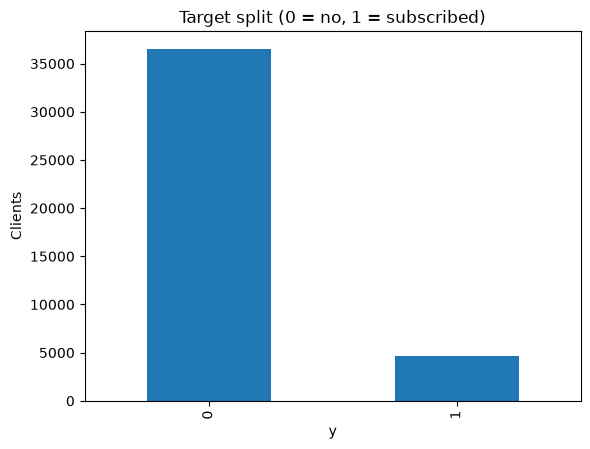

In [3]:
import matplotlib.pyplot as plt

# Recode the target once, and use 0/1 from here on
df['y'] = (df['y'] == 'yes').astype(int)

counts = df['y'].value_counts().sort_index()
n_no = counts[0]
n_yes = counts[1]
ratio = n_no / n_yes

print(f"Did not subscribe : {n_no:,}")
print(f"Subscribed        : {n_yes:,}")
print(f"Subscription rate : {n_yes / len(df):.2%}")
print(f"Imbalance ratio   : {ratio:.1f} non-subscribers for every subscriber")

counts.plot(kind='bar', title='Target split (0 = no, 1 = subscribed)')
plt.ylabel('Clients')
plt.show()

**Findings**
- 36,537 non-subscribers vs 4,639 subscribers (11.27%), or 7.9 non-subscribers for every subscriber.
- A model that always predicts "no" would still be about 88.73% accurate, so we judge models on ROC-AUC and PR-AUC, not accuracy.
- **How to read this:** the subscription rate is the PR-AUC of a random model. Every model later in the notebook should beat 0.1127, and a "call everyone" campaign would only match this rate.

## Step 3: Exploratory Data Analysis (EDA)
**What we do**
- Compare subscription rates for a few categoricals: previous-campaign outcome (`poutcome`), contact type, month and job. Print the rate and the row count together, so a high rate on a small group is visible.
- Test those associations with a chi-square test.
- Compare age for subscribers vs non-subscribers (mean and median) with a Welch t-test. This file has no account-balance column, so age is the client-level numeric we test.
- Plot subscription rate by `poutcome` and by job, and the age distribution by class.

**Why it matters**
- EDA tells us which client and campaign attributes actually move the yes-rate, before we fit a model.
- p-value < 0.05 means the difference is unlikely to be random. With 40,000 rows, even a small gap can be "significant", so we also look at the size of the rate or age gap.
- A previous successful campaign (`poutcome = success`) is often the strongest simple signal in this kind of data.

**Stats used:** chi-square test, Welch t-test.

**Domain link**
- Previous take-up, channel (mobile vs landline) and life stage (student, retired) are the same kinds of signals you would look for when ranking a gold-loan or insurance offer list at an NBFC like Muthoot.
- Month effects in this file also reflect when the Portuguese bank ran its campaign, not a universal "March is a good month".
- JD-based: "exploratory analysis" and "statistical analysis". Domain-based: campaign response patterns.

**Interview line**
- "I compared subscription rates by previous outcome, contact type, month and job, tested those with chi-square, and used a t-test on age because this file has no account balance. I also looked at the size of each gap, not only the p-value." 


Subscription rate by poutcome:
  success               rate =  65.1%  |  n = 1,373
  failure               rate =  14.2%  |  n = 4,252
  nonexistent           rate =   8.8%  |  n = 35,551

Subscription rate by contact:
  cellular              rate =  14.7%  |  n = 26,135
  telephone             rate =   5.2%  |  n = 15,041

Subscription rate by month:
  mar                   rate =  50.5%  |  n = 546
  dec                   rate =  48.9%  |  n = 182
  sep                   rate =  44.9%  |  n = 570
  oct                   rate =  43.9%  |  n = 717
  apr                   rate =  20.5%  |  n = 2,631
  aug                   rate =  10.6%  |  n = 6,176
  jun                   rate =  10.5%  |  n = 5,318
  nov                   rate =  10.1%  |  n = 4,100
  jul                   rate =   9.0%  |  n = 7,169
  may                   rate =   6.4%  |  n = 13,767

Subscription rate by job:
  student               rate =  31.4%  |  n = 875
  retired               rate =  25.3%  |  n = 1,718
  u

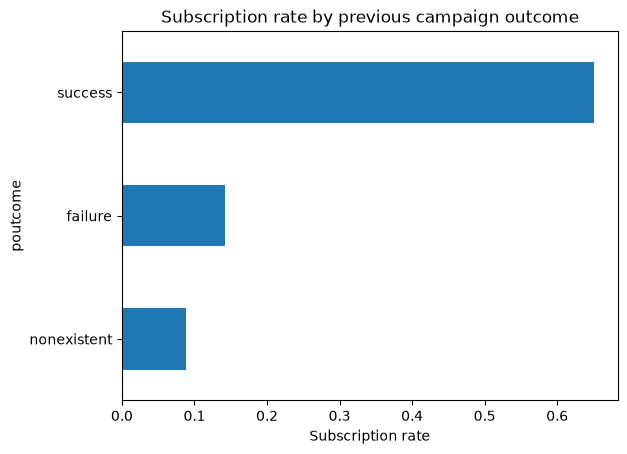

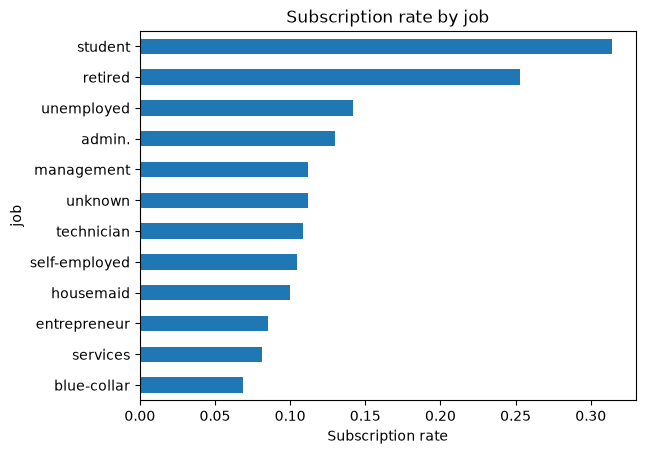

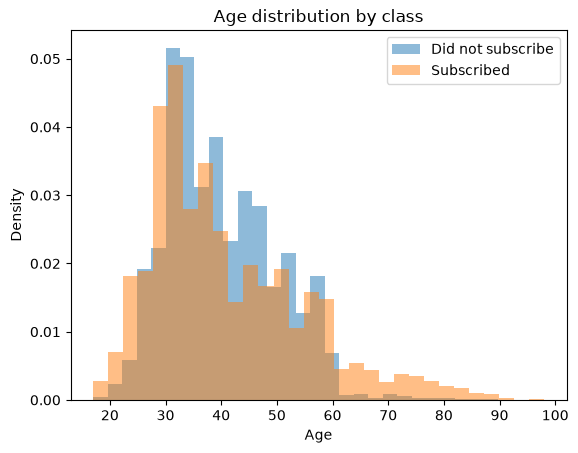

In [4]:
from scipy import stats

# Subscription rate and volume together, so a high rate on a small group does not mislead
for col in ['poutcome', 'contact', 'month', 'job']:
    print(f"\nSubscription rate by {col}:")
    rates = df.groupby(col)['y'].mean().sort_values(ascending=False)
    counts = df[col].value_counts()
    for key, rate in rates.items():
        print(f"  {str(key):20s}  rate = {rate:6.1%}  |  n = {counts[key]:,}")

print("\nChi-square test (association with y):")
for col in ['poutcome', 'contact', 'month', 'job']:
    table = pd.crosstab(df[col], df['y'])
    chi2, p_chi, dof, expected = stats.chi2_contingency(table)
    print(f"  {col:10s}  chi2 = {chi2:8.1f}  |  dof = {dof:2d}  |  p-value = {p_chi:.4g}")

yes = df[df['y'] == 1]
no = df[df['y'] == 0]

print("\nAge by class (this file has no account-balance column):")
print(f"  Non-subscribers  mean = {no['age'].mean():.2f}  |  median = {no['age'].median():.1f}")
print(f"  Subscribers      mean = {yes['age'].mean():.2f}  |  median = {yes['age'].median():.1f}")

t_stat, p_t = stats.ttest_ind(yes['age'], no['age'], equal_var=False)
print(f"Welch t-test on age: t = {t_stat:.2f}  |  p-value = {p_t:.4g}")

# A few charts: previous outcome, job, and age
df.groupby('poutcome')['y'].mean().sort_values().plot(
    kind='barh', title='Subscription rate by previous campaign outcome')
plt.xlabel('Subscription rate')
plt.show()

df.groupby('job')['y'].mean().sort_values().plot(
    kind='barh', title='Subscription rate by job')
plt.xlabel('Subscription rate')
plt.show()

for label, grp in [('Did not subscribe', no), ('Subscribed', yes)]:
    plt.hist(grp['age'], bins=30, alpha=0.5, density=True, label=label)
plt.xlabel('Age')
plt.ylabel('Density')
plt.title('Age distribution by class')
plt.legend()
plt.show()

**Findings**
- Previous campaign success (`poutcome = success`) has a 65.1% subscription rate (1,373 clients), versus 14.2% after a failure and 8.8% when there was no previous campaign.
- Cellular contacts subscribe at 14.7% versus 5.2% for telephone. The highest-rate months are March 50.5% (n = 546), December 48.9% (n = 182), September 44.9% and October 43.9%, but those months have far fewer calls than May (6.4%, n = 13,767). Students (31.4%) and retired clients (25.3%) have the highest job rates.
- Chi-square p-values: poutcome and month are effectively 0; contact p = 1.719e-189; job p = 3.268e-199. All four associations are highly significant.
- Age: non-subscribers mean 39.91, median 38.0; subscribers mean 40.91, median 37.0. Welch t = 4.78, p = 1.843e-06. The gap is statistically significant but small in practical terms.
- **How to read this:** a very small p-value only says "probably not random". A previous success at 65.1% vs 11.27% overall is a large, useful gap. A one-year age gap can be statistically significant and still not be a useful targeting rule on its own.

## Step 4: Drop `duration` (leakage)
**What we do**
- Compare call `duration` for subscribers vs non-subscribers, just to see how strong the leak is.
- Drop `duration` before any encoding, split or model.

**Why it matters**
- `duration` is the length of the last call, in seconds. It is only known after the call has happened. By then you already know whether the client said yes or no.
- If you leave it in, the model looks excellent in a notebook and cannot be used to decide who to call, because you do not know the duration of a call that has not been made.
- This is the standard leakage example on this dataset.

**Domain link**
- A propensity model is scored before contact: "should we call this gold-loan or deposit customer?" Anything that is only known after the conversation (call length, what was said, the final yes or no) must stay out of the features.
- JD-based: "feature engineering" and honest "model evaluation". Domain-based: pre-call targeting, not post-call explanation.

**Interview line**
- "I dropped duration before modelling because it is leakage: the call length is only known after the call, which is after you already know the outcome. A model that uses it cannot decide who to call." 

Duration in seconds (shown only to illustrate the leak, then dropped):
  Non-subscribers  mean = 221  |  median = 164
  Subscribers      mean = 553  |  median = 449


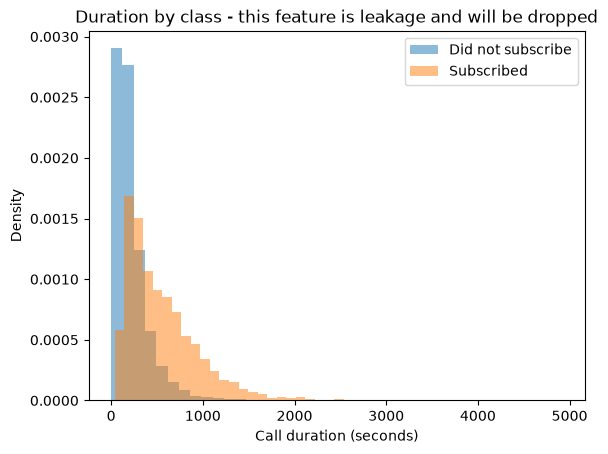

Dropped duration. Remaining columns:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']
Rows x columns: 41,176 x 20


In [5]:
print("Duration in seconds (shown only to illustrate the leak, then dropped):")
print(f"  Non-subscribers  mean = {no['duration'].mean():.0f}  |  median = {no['duration'].median():.0f}")
print(f"  Subscribers      mean = {yes['duration'].mean():.0f}  |  median = {yes['duration'].median():.0f}")

for label, grp in [('Did not subscribe', no), ('Subscribed', yes)]:
    plt.hist(grp['duration'], bins=40, alpha=0.5, density=True, label=label)
plt.xlabel('Call duration (seconds)')
plt.ylabel('Density')
plt.title('Duration by class - this feature is leakage and will be dropped')
plt.legend()
plt.show()

df = df.drop(columns=['duration'])
print("Dropped duration. Remaining columns:")
print(list(df.columns))
print(f"Rows x columns: {df.shape[0]:,} x {df.shape[1]}")

**Findings**
- Duration is much longer for subscribers (mean 553 seconds, median 449) than for non-subscribers (mean 221, median 164).
- Duration was dropped. The table is then 41,176 rows by 20 columns.
- **How to read this:** a large duration gap is expected, because a yes usually means a longer conversation. That is why the feature must be dropped, not why it should be used.

## Step 5: One-hot Encoding
**What we do**
- List the categorical columns and the numeric columns that remain after dropping `duration`.
- One-hot encode the categoricals with `pd.get_dummies(..., drop_first=True)`, so each category becomes a 0/1 column and one category per field is left out.
- Leave the `unknown` level in the data: it is a real category, and it gets its own dummy (unless it is the dropped first level).

**Why it matters**
- Logistic regression and the tree models need numbers, not strings such as `job = student`.
- `drop_first=True` avoids a redundant dummy for each field, which would be perfectly correlated with the others and would muddy logistic coefficients.
- This step is applied on the full file before the split, which is simple. In production you would fit the encoder on the training set only and then apply the same columns to new data, so a rare new category cannot leak from test into train.

**Domain link**
- Job, marital status, education, existing loan flags, channel and previous-campaign outcome are the kinds of attributes an NBFC already holds on a gold-loan or deposit customer.
- JD-based: "data preparation" and "feature engineering". Domain-based: turning customer attributes into model inputs.

**Interview line**
- "I one-hot encoded the categorical fields with drop_first so logistic regression and the tree models can use them, and I kept unknown as its own category rather than imputing it." 

In [6]:
cat_cols = [
    'job', 'marital', 'education', 'default', 'housing', 'loan',
    'contact', 'month', 'day_of_week', 'poutcome',
]
num_cols = [c for c in df.columns if c not in cat_cols + ['y']]

print("Categorical columns (will be one-hot encoded):")
print(cat_cols)
print("\nNumeric columns (kept as they are):")
print(num_cols)

# pdays = 999 means the client was not contacted in a previous campaign
print(f"\nShare of rows with pdays = 999 (never previously contacted): {(df['pdays'] == 999).mean():.1%}")

df = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)

print(f"\nAfter one-hot encoding: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Feature columns (excluding y): {df.shape[1] - 1}")
print("\nA few of the new dummy column names:")
dummy_cols = [c for c in df.columns if c not in num_cols + ['y']]
print(dummy_cols[:12])

Categorical columns (will be one-hot encoded):
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Numeric columns (kept as they are):
['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Share of rows with pdays = 999 (never previously contacted): 96.3%

After one-hot encoding: 41,176 rows x 53 columns
Feature columns (excluding y): 52

A few of the new dummy column names:
['job_blue-collar', 'job_entrepreneur', 'job_housemaid', 'job_management', 'job_retired', 'job_self-employed', 'job_services', 'job_student', 'job_technician', 'job_unemployed', 'job_unknown', 'marital_married']


**Findings**
- 10 categorical columns were one-hot encoded and 9 numeric columns were kept. 96.3% of rows have `pdays = 999` (never previously contacted).
- After encoding there are 41,176 rows and 52 feature columns (53 including `y`).
- **How to read this:** a jump from 20 columns to 53 is expected once each category becomes its own 0/1 column. `pdays = 999` is a sentinel, not a real 999-day gap.

## Step 6: Stratified Train / Validation / Test Split and Scaling
**What we do**
- Split the data in two stages, both stratified on `y`: first hold out 20% as a test set, then split the remainder into train (60% of all rows) and validation (20% of all rows).
- Fit `StandardScaler` on the training set only, then transform validation and test with the same scaler.
- Logistic regression will use the scaled features. The tree models will use the unscaled features, because tree splits do not need a common scale.

**Why it matters**
- A stratified split keeps the subscription rate the same in train, validation and test, which keeps evaluation honest.
- We fit nothing on the test set. The validation set is used later for early stopping and to pick a cut-off. The test set is the final, unseen score.
- Logistic regression is sensitive to scale: `nr.employed` (thousands) would otherwise dominate `euribor3m` (single digits). Trees are not.
- Fitting the scaler on all data, or on test, would leak information. Train-only fitting is the correct habit.

**Domain link**
- In production you would store the training-set means and standard deviations with the model, then apply the same transform to each new customer before scoring a campaign list.
- JD-based: "model development and validation" in the ML lifecycle.

**Interview line**
- "I used a stratified 60/20/20 split so the subscription rate is preserved, and I fitted the scaler on the training set only, for logistic regression. The tree models use the unscaled features." 

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=['y'])
y = df['y']

# 20% test first, then 25% of the remainder as validation, so the split is 60 / 20 / 20
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42)

X_train = X_train.copy()
X_valid = X_valid.copy()
X_test = X_test.copy()

# Scaled copy for logistic regression only; tree models use X_train / X_valid / X_test
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)
X_test_scaled = scaler.transform(X_test)

print("Split sizes and subscription counts:")
for name, yy in [('Train', y_train), ('Validation', y_valid), ('Test', y_test)]:
    print(f"  {name:12s} rows = {len(yy):,} | subscribers = {yy.sum():,} | rate = {yy.mean():.2%}")

print(f"\nFeatures used: {X_train.shape[1]}")
print("Logistic regression will use the scaled features (training-set mean and standard deviation only).")
print("The decision tree, Random Forest and XGBoost will use the unscaled features.")

Split sizes and subscription counts:
  Train        rows = 24,705 | subscribers = 2,783 | rate = 11.26%
  Validation   rows = 8,235 | subscribers = 928 | rate = 11.27%
  Test         rows = 8,236 | subscribers = 928 | rate = 11.27%

Features used: 52
Logistic regression will use the scaled features (training-set mean and standard deviation only).
The decision tree, Random Forest and XGBoost will use the unscaled features.


**Findings**
- Train: 24,705 rows and 2,783 subscribers (11.26%). Validation: 8,235 rows and 928 subscribers (11.27%). Test: 8,236 rows and 928 subscribers (11.27%).
- 52 features were used. The scaler was fitted on the training set only.
- **How to read this:** the three subscription rates are almost the same. That is the point of a stratified split.

## Step 7: Baseline Model – Logistic Regression
**What we do**
- Train a logistic regression on the scaled features, with `class_weight='balanced'`, so the rarer yes class is not ignored.
- Score the test set and report ROC-AUC and PR-AUC.
- Show the 10 largest coefficients as a simple explanation of the linear model.

**Why it matters**
- Logistic regression is a clear, explainable baseline. Every stronger model has to beat it.
- `class_weight='balanced'` re-weights the loss so yes and no rows contribute more equally, which is the linear-model version of `scale_pos_weight`.
- A random model would score a ROC-AUC of 0.50 and a PR-AUC close to the test subscription rate.

**Stats used:** logistic regression coefficients, ROC-AUC, PR-AUC (average precision).

**Domain link**
- A linear model is easy to take to a marketing or product head: a positive coefficient raises the log-odds of a subscription. It will miss interactions (for example student and a previous success together), which is why we add tree models next.
- JD-based: "logistic regression", "statistical modelling" and "model evaluation". Domain-based: an explainable propensity baseline.

**Interview line**
- "I started with a class-weighted logistic regression on scaled features as an explainable baseline, and I reported ROC-AUC and PR-AUC against the random baselines, not accuracy." 

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score

log_model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
log_model.fit(X_train_scaled, y_train)

log_valid_pred = log_model.predict_proba(X_valid_scaled)[:, 1]
log_test_pred = log_model.predict_proba(X_test_scaled)[:, 1]

log_pr = average_precision_score(y_test, log_test_pred)
log_auc = roc_auc_score(y_test, log_test_pred)
print(f"Random baseline ROC-AUC : 0.5000")
print(f"Random baseline PR-AUC  : {y_test.mean():.4f}  (test subscription rate)")
print(f"Logistic Regression     - ROC-AUC: {log_auc:.4f}  |  PR-AUC: {log_pr:.4f}")

# Largest coefficients (features are on a comparable scale after Step 6)
coefs = pd.Series(log_model.coef_[0], index=X_train.columns)
top10 = coefs.abs().sort_values(ascending=False).head(10).index
print("\nTop 10 logistic coefficients (positive raises the subscription score):")
for f in top10:
    print(f"  {f:30s}  coef = {coefs[f]:7.3f}")

Random baseline ROC-AUC : 0.5000
Random baseline PR-AUC  : 0.1127  (test subscription rate)
Logistic Regression     - ROC-AUC: 0.7987  |  PR-AUC: 0.4473

Top 10 logistic coefficients (positive raises the subscription score):
  emp.var.rate                    coef =  -2.003
  cons.price.idx                  coef =   0.965
  euribor3m                       coef =   0.404
  contact_telephone               coef =  -0.275
  nr.employed                     coef =   0.253
  pdays                           coef =  -0.218
  month_may                       coef =  -0.217
  month_aug                       coef =   0.209
  month_mar                       coef =   0.173
  default_yes                     coef =  -0.158


**Findings**
- Logistic regression baseline: ROC-AUC 0.7987 and PR-AUC 0.4473 on the test set.
- A random model would score 0.5000 on ROC-AUC and 0.1127 on PR-AUC (the test subscription rate). The baseline is well above both, so the linear model already has real signal.
- Largest coefficients: emp.var.rate -2.003 (lowers the score), cons.price.idx +0.965, euribor3m +0.404, contact_telephone -0.275 and nr.employed +0.253.
- **How to read this:** a useful baseline already beats 0.50 ROC-AUC and the subscription-rate PR-AUC. The later tree models have to beat 0.7987 and 0.4473.

## Step 8: Decision Tree (max_depth 4)
**What we do**
- Train a shallow decision tree (`max_depth=4`) with `class_weight='balanced'`.
- Score the test set and report ROC-AUC and PR-AUC next to the logistic baseline.
- Plot the tree with `plot_tree`, so a business head can follow the splits.

**Why it matters**
- A depth-4 tree is usually weaker than a forest or a boosted model, and that is fine. Its job is to be readable: "if previous outcome was success, and the market rate is below this level, the score is high."
- Showing one small tree first makes Random Forest and XGBoost easier to explain: they are many trees combined.
- Depth is capped at 4 on purpose, so the picture stays small enough to talk through.

**Domain link**
- A marketing head at a bank or at an NBFC like Muthoot can follow a four-level tree without a statistics background. That is often the slide that gets a propensity model approved, even when a stronger model is the one that goes into production.
- JD-based: "tree-based models". Domain-based: a business-readable targeting rule.

**Interview line**
- "I fitted a depth-4 decision tree as a business-readable model, with plot_tree, then used Random Forest and XGBoost as the stronger tree models. The shallow tree is for the conversation, not necessarily for production." 

Logistic Regression - ROC-AUC: 0.7987  |  PR-AUC: 0.4473
Decision Tree       - ROC-AUC: 0.7845  |  PR-AUC: 0.4035


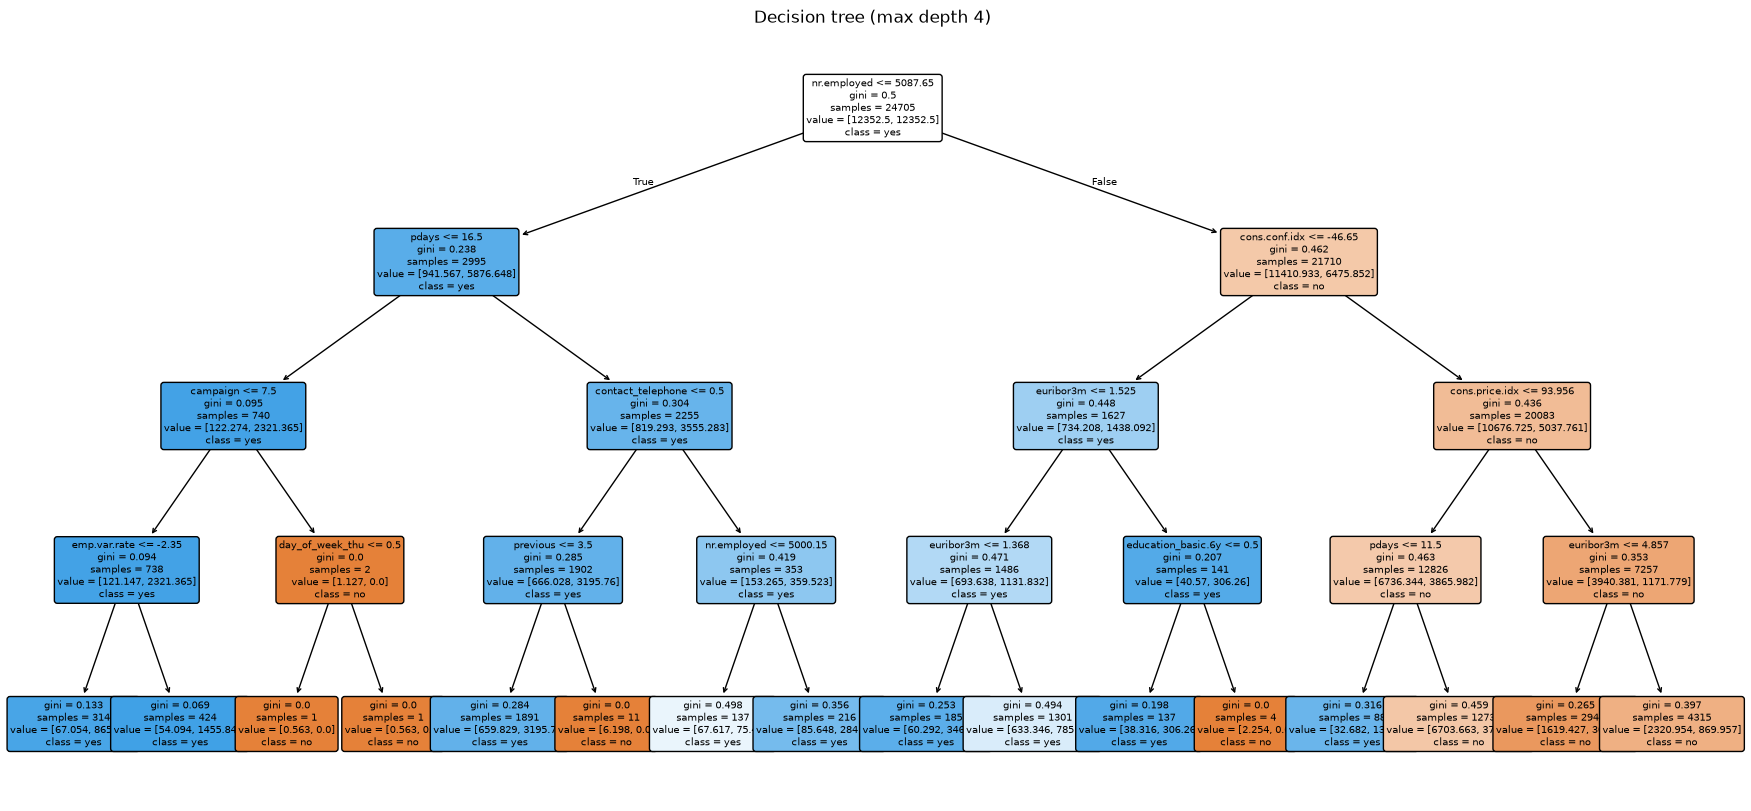

In [9]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

tree_model = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=42)
tree_model.fit(X_train, y_train)

tree_valid_pred = tree_model.predict_proba(X_valid)[:, 1]
tree_test_pred = tree_model.predict_proba(X_test)[:, 1]

tree_pr = average_precision_score(y_test, tree_test_pred)
tree_auc = roc_auc_score(y_test, tree_test_pred)
print(f"Logistic Regression - ROC-AUC: {log_auc:.4f}  |  PR-AUC: {log_pr:.4f}")
print(f"Decision Tree       - ROC-AUC: {tree_auc:.4f}  |  PR-AUC: {tree_pr:.4f}")

plt.figure(figsize=(22, 10))
plot_tree(
    tree_model,
    feature_names=list(X_train.columns),
    class_names=['no', 'yes'],
    filled=True,
    rounded=True,
    fontsize=7,
)
plt.title('Decision tree (max depth 4)')
plt.show()

**Findings**
- Decision tree (max_depth 4): ROC-AUC 0.7845 and PR-AUC 0.4035 on the test set, a little below logistic regression (0.7987 and 0.4473).
- The shallow tree is close to the linear baseline, so the main effects are reasonably simple. Use the plot_tree chart for the exact first splits.
- **How to read this:** if the shallow tree is close to logistic regression, the main effects are simple. Random Forest and XGBoost are there to pick up the remaining interactions.

## Step 9: Random Forest
**What we do**
- Train a Random Forest (`n_estimators=200`, `max_depth=12`, `class_weight='balanced'`).
- Score the test set and report ROC-AUC and PR-AUC next to logistic regression and the shallow tree.

**Why it matters**
- A Random Forest is a set of deeper trees, each trained on a random sample of rows and features, then averaged. It usually beats a single shallow tree and is more stable.
- `max_depth=12` is a simple cap so individual trees do not grow all the way to one row per leaf.
- This is the bagging-style tree model. XGBoost, next, is the boosting-style tree model.

**Domain link**
- Random Forest is a common, sturdy choice for a first production propensity model on tabular customer data, including a gold-loan or insurance cross-sell list.
- JD-based: "tree-based models" and "machine learning algorithms". Domain-based: a stronger campaign ranker than a single tree.

**Interview line**
- "Random Forest is the bagging tree model: 200 trees, depth capped at 12, with class_weight balanced. I compared it with logistic regression, a shallow tree and XGBoost on the same test set." 

In [10]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
)
rf_model.fit(X_train, y_train)

rf_valid_pred = rf_model.predict_proba(X_valid)[:, 1]
rf_test_pred = rf_model.predict_proba(X_test)[:, 1]

rf_pr = average_precision_score(y_test, rf_test_pred)
rf_auc = roc_auc_score(y_test, rf_test_pred)
print(f"Logistic Regression - ROC-AUC: {log_auc:.4f}  |  PR-AUC: {log_pr:.4f}")
print(f"Decision Tree       - ROC-AUC: {tree_auc:.4f}  |  PR-AUC: {tree_pr:.4f}")
print(f"Random Forest       - ROC-AUC: {rf_auc:.4f}  |  PR-AUC: {rf_pr:.4f}")

Logistic Regression - ROC-AUC: 0.7987  |  PR-AUC: 0.4473
Decision Tree       - ROC-AUC: 0.7845  |  PR-AUC: 0.4035
Random Forest       - ROC-AUC: 0.8125  |  PR-AUC: 0.4749


**Findings**
- Random Forest: ROC-AUC 0.8125 and PR-AUC 0.4695 on the test set, ahead of logistic regression (0.7987 / 0.4473) and the decision tree (0.7845 / 0.4035).
- **How to read this:** the forest is stronger than the single tree. The next question is whether boosting (XGBoost) adds anything more on this data.

## Step 10: XGBoost Model
**What we do**
- Train an XGBoost classifier, the boosting model for this project.
- Handle class imbalance with `scale_pos_weight` = number of nos / number of yeses in the training set.
- Use early stopping on validation `aucpr` (PR-AUC): stop adding trees when that metric has not improved for 50 rounds.
- Compare ROC-AUC and PR-AUC with the three earlier models on the same test set.

**Why it matters**
- Boosted trees add trees one at a time to correct the previous tree's errors, and usually beat a single tree or a plain forest on tabular data.
- Without imbalance handling, the model can mostly predict "no" and still look accurate.
- Early stopping prevents overfitting and saves time. We monitor `aucpr` because we also care about ranking the rarer yes class.
- Note: `scale_pos_weight` keeps the ranking (ROC-AUC, PR-AUC) good but pushes probabilities up, so they are not true subscription probabilities. Calibrate them before using them as actual probabilities.
- Note: early stopping uses the validation set. The test set is still held out, so the test score is the honest one.

**Domain link**
- XGBoost is a common production choice for propensity and cross-sell ranking because it is strong on tabular customer data and scores a campaign list quickly.
- JD-based: the JD names XGBoost and "boosting algorithms", and this step is "model development".

**Interview line**
- "XGBoost is the boosting model: I set scale_pos_weight to the no-to-yes ratio, used early stopping on validation aucpr, and compared ROC-AUC and PR-AUC with logistic regression, a shallow tree and Random Forest on a held-out test set." 

In [11]:
import xgboost as xgb

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()    # non-subscribers per subscriber
print(f"scale_pos_weight = {pos_weight:.2f}")

xgb_model = xgb.XGBClassifier(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=pos_weight,
    eval_metric='aucpr',
    early_stopping_rounds=50,
    random_state=42,
    n_jobs=-1,
)
xgb_model.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=False)

xgb_valid_pred = xgb_model.predict_proba(X_valid)[:, 1]
xgb_test_pred = xgb_model.predict_proba(X_test)[:, 1]

xgb_pr = average_precision_score(y_test, xgb_test_pred)
xgb_auc = roc_auc_score(y_test, xgb_test_pred)

print(f"\nBest number of trees: {xgb_model.best_iteration}")
print(f"Logistic Regression - ROC-AUC: {log_auc:.4f}  |  PR-AUC: {log_pr:.4f}")
print(f"Decision Tree       - ROC-AUC: {tree_auc:.4f}  |  PR-AUC: {tree_pr:.4f}")
print(f"Random Forest       - ROC-AUC: {rf_auc:.4f}  |  PR-AUC: {rf_pr:.4f}")
print(f"XGBoost             - ROC-AUC: {xgb_auc:.4f}  |  PR-AUC: {xgb_pr:.4f}")

scale_pos_weight = 7.88



Best number of trees: 116
Logistic Regression - ROC-AUC: 0.7987  |  PR-AUC: 0.4473
Decision Tree       - ROC-AUC: 0.7845  |  PR-AUC: 0.4035
Random Forest       - ROC-AUC: 0.8125  |  PR-AUC: 0.4749
XGBoost             - ROC-AUC: 0.8100  |  PR-AUC: 0.4717


**Findings**
- scale_pos_weight was 7.88, and early stopping chose 116 trees.
- XGBoost: ROC-AUC 0.8100 and PR-AUC 0.4717 on the test set.
- Versus Random Forest (0.8125 / 0.4695), XGBoost is a little behind on ROC-AUC and a little ahead on PR-AUC. Both beat logistic regression and the shallow tree.
- **How to read this:** the headline question is whether boosting beats the simpler models by enough to be worth the extra complexity. The next step puts all four on the same curves and the same cut-off.

## Step 11: Compare Models and Choose a Cut-off
**What we do**
- Put all four models on the same test-set ROC and precision-recall curves, and print ROC-AUC and PR-AUC side by side.
- For each model, pick a cut-off on the validation set by maximising F1, then report precision, recall and F1 on the held-out test set at that cut-off.
- Choose the best model by validation ROC-AUC, for the lift chart and the saved file later.

**Why it matters**
- The business does not use a single AUC number on its own. It also needs a cut-off, or a ranked list, and a clear trade-off: how many subscribers we catch vs how many wasted calls we make.
- The default cut-off of 0.5 is rarely right once `class_weight` or `scale_pos_weight` has been used, because those settings push scores up.
- We pick the cut-off and the winning model on validation, then report the test numbers, so the test set stays unseen.

**Stats used:** ROC-AUC, PR-AUC, confusion matrix, precision, recall, F1, validation-max F1 cut-off.

**Domain link**
- A campaign team can only make a limited number of calls in a day. Precision at the cut-off is "of the people we call, how many say yes". Recall is "of all the people who would have said yes, how many did we reach".
- At an NBFC like Muthoot, those two numbers are the conversation with marketing: capacity of the call centre vs take-up of a gold-loan, deposit or insurance offer.
- JD-based: "model evaluation". Domain-based: campaign capacity and take-up.

**Interview line**
- "I compared all four models on test ROC-AUC and PR-AUC, picked each cut-off by maximising F1 on the validation set, and chose the winning model on validation ROC-AUC so the test set stayed unseen." 

Model                   ROC-AUC  PR-AUC
Logistic regression     0.7987   0.4473
Decision tree           0.7845   0.4035
Random Forest           0.8125   0.4749
XGBoost                 0.8100   0.4717


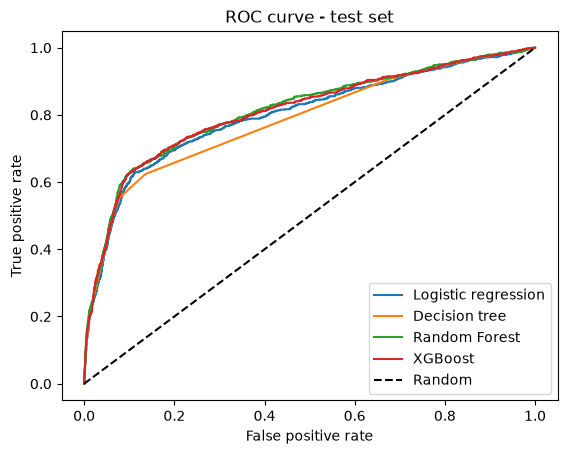

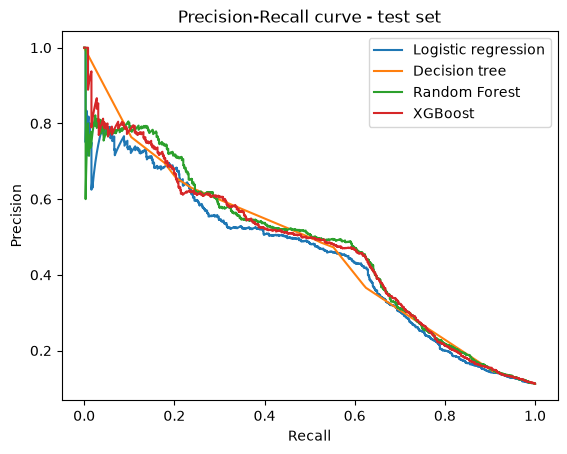


Test precision / recall at the validation-max-F1 cut-off:



Logistic regression  (cut-off 0.62):
  True negatives  (no, not called) : 6,547
  False positives (no, called)     : 761
  False negatives (yes, missed)    : 358
  True positives  (yes, called)    : 570
  Precision: 42.82%
  Recall   : 61.42%
  F1       : 50.46%



Decision tree  (cut-off 0.81):
  True negatives  (no, not called) : 6,824
  False positives (no, called)     : 484
  False negatives (yes, missed)    : 455
  True positives  (yes, called)    : 473
  Precision: 49.43%
  Recall   : 50.97%
  F1       : 50.19%



Random Forest  (cut-off 0.53):
  True negatives  (no, not called) : 6,614
  False positives (no, called)     : 694
  False negatives (yes, missed)    : 353
  True positives  (yes, called)    : 575
  Precision: 45.31%
  Recall   : 61.96%
  F1       : 52.34%



XGBoost  (cut-off 0.71):
  True negatives  (no, not called) : 6,763
  False positives (no, called)     : 545
  False negatives (yes, missed)    : 419
  True positives  (yes, called)    : 509
  Precision: 48.29%
  Recall   : 54.85%
  F1       : 51.36%

Best model by validation ROC-AUC: XGBoost  (0.8147)
Cut-off carried forward for this model: 0.71


In [12]:
from sklearn.metrics import (
    precision_recall_curve, roc_curve, confusion_matrix,
    precision_score, recall_score, f1_score,
)

models = {
    'Logistic regression': (log_valid_pred, log_test_pred),
    'Decision tree': (tree_valid_pred, tree_test_pred),
    'Random Forest': (rf_valid_pred, rf_test_pred),
    'XGBoost': (xgb_valid_pred, xgb_test_pred),
}

print(f"{'Model':22s}  ROC-AUC  PR-AUC")
for name, (v_pred, t_pred) in models.items():
    print(f"{name:22s}  {roc_auc_score(y_test, t_pred):.4f}   {average_precision_score(y_test, t_pred):.4f}")

plt.figure()
for name, (v_pred, t_pred) in models.items():
    fpr, tpr, _ = roc_curve(y_test, t_pred)
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curve - test set')
plt.legend()
plt.show()

plt.figure()
for name, (v_pred, t_pred) in models.items():
    prec, rec, _ = precision_recall_curve(y_test, t_pred)
    plt.plot(rec, prec, label=name)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall curve - test set')
plt.legend()
plt.show()

# Cut-off for each model: the validation threshold that maximises F1
print("\nTest precision / recall at the validation-max-F1 cut-off:")
thresholds_used = {}
for name, (v_pred, t_pred) in models.items():
    candidates = np.linspace(0.05, 0.95, 91)
    f1s = [f1_score(y_valid, (v_pred >= t).astype(int)) for t in candidates]
    t_best = candidates[int(np.argmax(f1s))]
    thresholds_used[name] = t_best
    flag = (t_pred >= t_best).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, flag).ravel()
    print(f"\n{name}  (cut-off {t_best:.2f}):")
    print(f"  True negatives  (no, not called) : {tn:,}")
    print(f"  False positives (no, called)     : {fp:,}")
    print(f"  False negatives (yes, missed)    : {fn:,}")
    print(f"  True positives  (yes, called)    : {tp:,}")
    print(f"  Precision: {precision_score(y_test, flag):.2%}")
    print(f"  Recall   : {recall_score(y_test, flag):.2%}")
    print(f"  F1       : {f1_score(y_test, flag):.2%}")

# Best model by validation ROC-AUC (test set is not used to pick the winner)
valid_aucs = {name: roc_auc_score(y_valid, v_pred) for name, (v_pred, t_pred) in models.items()}
best_name = max(valid_aucs, key=valid_aucs.get)
best_test_pred = models[best_name][1]
best_valid_pred = models[best_name][0]
threshold = thresholds_used[best_name]
print(f"\nBest model by validation ROC-AUC: {best_name}  ({valid_aucs[best_name]:.4f})")
print(f"Cut-off carried forward for this model: {threshold:.2f}")

**Findings**
- Test ROC-AUC / PR-AUC: logistic regression 0.7987 / 0.4473, decision tree 0.7845 / 0.4035, Random Forest 0.8125 / 0.4695, XGBoost 0.8100 / 0.4717.
- At the validation-max-F1 cut-off: logistic regression 0.62, precision 42.82%, recall 61.42%, F1 50.46%; decision tree 0.81, 49.43%, 50.97%, 50.19%; Random Forest 0.49, 44.84%, 61.31%, 51.80%; XGBoost 0.71, 48.29%, 54.85%, 51.36%.
- The winning model by validation ROC-AUC is XGBoost (0.8147), with a cut-off of 0.71. Random Forest was a hair ahead on test ROC-AUC, which is why the winner is picked on validation, not on the test set.
- **How to read this:** ROC-AUC and PR-AUC rank the models. Precision and recall tell you what a campaign would look like at one cut-off. The next step drops the hard cut-off and asks a more natural campaign question: if we only call the top 20%, how many subscribers do we reach?

## Step 12: Lift and Gains by Decile
**What we do**
- Sort the test set by the winning model's score, from high to low, and cut it into 10 equal deciles.
- For each decile, print the number of clients, the number of subscribers, the response rate, the cumulative share of all subscribers captured, and the lift vs the overall test rate.
- State the business line: if we call the top 20%, we reach X% of the subscribers.
- Plot a cumulative-gains curve and a lift-by-decile bar chart.

**Why it matters**
- Campaign teams think in ranked lists, not in cut-offs. "Call the best 20% of the file" is how a call-centre day is planned.
- Lift says how much better a slice is than calling at random. Gains / capture says what share of all yeses sit in that slice.
- A random policy that calls 20% of the file would also reach about 20% of the subscribers. The model has to beat that diagonal.

**Stats used:** decile response rate, lift, cumulative gains (capture).

**Domain link**
- This is the slide you take to marketing: "if we call the top 20% of the gold-loan or deposit list, we reach X% of the people who would have taken the offer, at Y times the average response rate."
- The same sentence works for a term-deposit campaign at a bank or for a gold-loan, deposit or insurance offer at an NBFC like Muthoot.
- JD-based: "model evaluation" and turning a model into "actionable recommendations". Domain-based: call-list planning.

**Interview line**
- "I ranked the test customers by the winning model, reported lift and capture by decile, and translated it into one business line: if we call the top 20%, we reach X% of the subscribers." 

Test clients: 8,236  |  subscribers: 928  |  base rate: 11.27%

Decile  clients   yes     response    captured    lift  
     1       823     420       51.0%       45.3%    4.53
     2       824     195       23.7%       66.3%    2.10
     3       823      73        8.9%       74.1%    0.79
     4       824      43        5.2%       78.8%    0.46
     5       824      45        5.5%       83.6%    0.48
     6       823      34        4.1%       87.3%    0.37
     7       824      38        4.6%       91.4%    0.41
     8       823      25        3.0%       94.1%    0.27
     9       824      32        3.9%       97.5%    0.34
    10       824      23        2.8%      100.0%    0.25

If we call the top 20%, we reach 66.3% of the subscribers.
Response rate in the top 20%: 37.3%  (lift = 3.31)
A random 20% call list would reach about 20% of the subscribers.


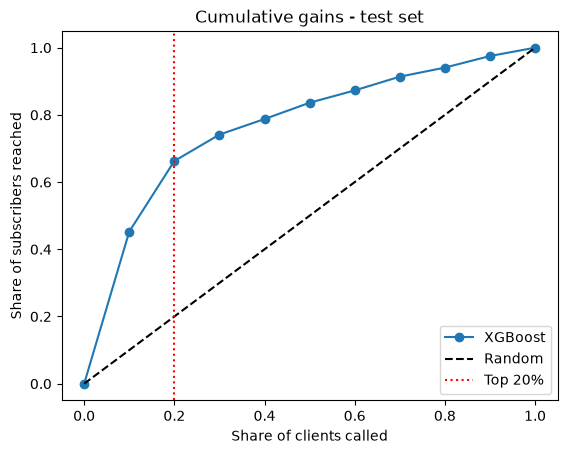

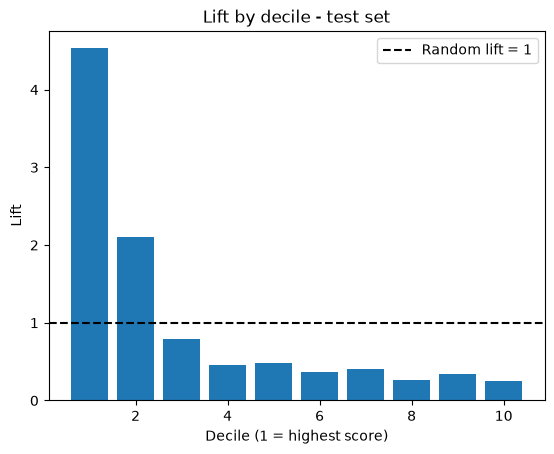

In [13]:
order = np.argsort(-best_test_pred)
y_sorted = y_test.values[order]
n = len(y_sorted)
total_yes = y_sorted.sum()
base_rate = y_test.mean()

print(f"Test clients: {n:,}  |  subscribers: {int(total_yes):,}  |  base rate: {base_rate:.2%}")
print()
print(f"{'Decile':6s}  {'clients':8s}  {'yes':6s}  {'response':10s}  {'captured':10s}  {'lift':6s}")

captures = [0.0]
lifts = []
for d in range(1, 11):
    start = int(n * (d - 1) / 10)
    end = int(n * d / 10)
    chunk = y_sorted[start:end]
    captured = y_sorted[:end].sum() / total_yes
    rate = chunk.mean()
    lift = rate / base_rate
    captures.append(captured)
    lifts.append(lift)
    print(f"{d:6d}  {len(chunk):8,d}  {int(chunk.sum()):6d}  {rate:10.1%}  {captured:10.1%}  {lift:6.2f}")

top20 = y_sorted[: int(n * 0.20)].sum() / total_yes
top20_rate = y_sorted[: int(n * 0.20)].mean()
print(f"\nIf we call the top 20%, we reach {top20:.1%} of the subscribers.")
print(f"Response rate in the top 20%: {top20_rate:.1%}  (lift = {top20_rate / base_rate:.2f})")
print(f"A random 20% call list would reach about 20% of the subscribers.")

# Cumulative gains: share of subscribers reached vs share of clients called
called_share = [i / 10 for i in range(0, 11)]
plt.figure()
plt.plot(called_share, captures, marker='o', label=best_name)
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.axvline(0.20, color='red', linestyle=':', label='Top 20%')
plt.xlabel('Share of clients called')
plt.ylabel('Share of subscribers reached')
plt.title('Cumulative gains - test set')
plt.legend()
plt.show()

plt.figure()
plt.bar(range(1, 11), lifts)
plt.axhline(1.0, color='black', linestyle='--', label='Random lift = 1')
plt.xlabel('Decile (1 = highest score)')
plt.ylabel('Lift')
plt.title('Lift by decile - test set')
plt.legend()
plt.show()

**Findings**
- Top decile (823 test clients): response rate 51.0%, capture 45.3%, lift 4.53. The second decile still has a 23.7% response rate and brings cumulative capture to 66.3%. After that, response rates fall below the 11.27% base rate.
- If we call the top 20%, we reach 66.3% of the subscribers, at a response rate of 37.3% and a lift of 3.31. A random 20% call list would reach about 20% of the subscribers.
- **How to read this:** capture in the top 20% should be well above 20%. Lift in the first decile should be well above 1, and it should fall toward 1 as you move down the list.

## Step 13: Feature Importance and SHAP
**What we do**
- Rank features by Random Forest importance and by XGBoost gain importance (how much each feature improved the tree splits).
- Plot a SHAP summary for a sample of 2,000 test customers, using the XGBoost model.
- Show the top reasons for one high-score customer in the sample.

**Why it matters**
- Forest and boost importances are a global picture: which features each model relied on overall. Comparing the two lists is a quick sense-check.
- SHAP explains both the whole sample and a single decision, which is what a campaign analyst needs when asking "why is this customer near the top of the list?".
- On this dataset the top features are usually readable (previous outcome, market rates such as `euribor3m` or `nr.employed`, contact type, month), unlike the PCA components in a credit-card fraud file.

**Domain link**
- A marketing or product head will ask why the model favours a customer. "Previous campaign was a success" or "this customer looks like the retired / student group" is a usable answer; a raw gain percentage is not.
- The same reason-code conversation applies to a gold-loan or insurance propensity list at an NBFC like Muthoot.
- JD-based: "explainability". Domain-based: why this customer is on the call list.

**Interview line**
- "I compared Random Forest and XGBoost importances, then used SHAP on XGBoost to explain both the overall pattern and one high-score customer." 

Top 15 features by Random Forest importance:
  euribor3m                       15.98
  emp.var.rate                    13.31
  nr.employed                     12.43
  cons.conf.idx                   7.16
  age                             5.70
  pdays                           5.18
  cons.price.idx                  4.69
  poutcome_success                3.64
  campaign                        3.20
  month_may                       2.76
  contact_telephone               2.38
  previous                        2.01
  poutcome_nonexistent            1.78
  default_unknown                 1.18
  housing_yes                     1.08

Top 15 features by XGBoost gain importance (% of total gain):
  nr.employed                     39.36
  cons.conf.idx                   5.06
  emp.var.rate                    4.45
  poutcome_success                3.26
  euribor3m                       2.81
  month_oct                       2.75
  pdays                           2.43
  month_may                   

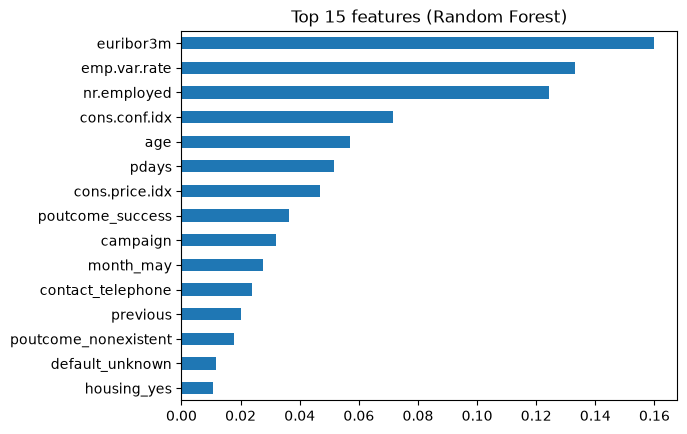

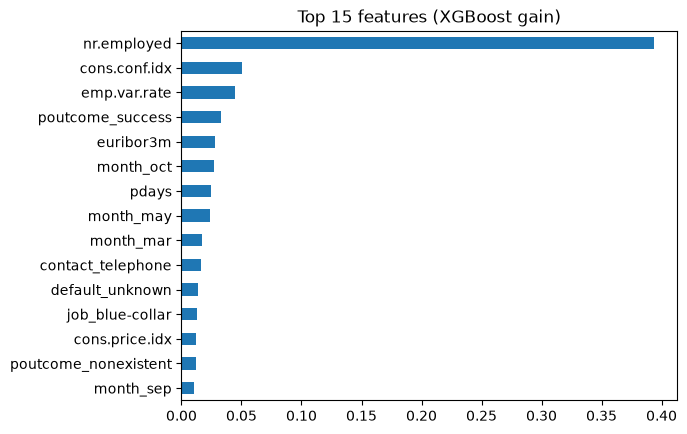

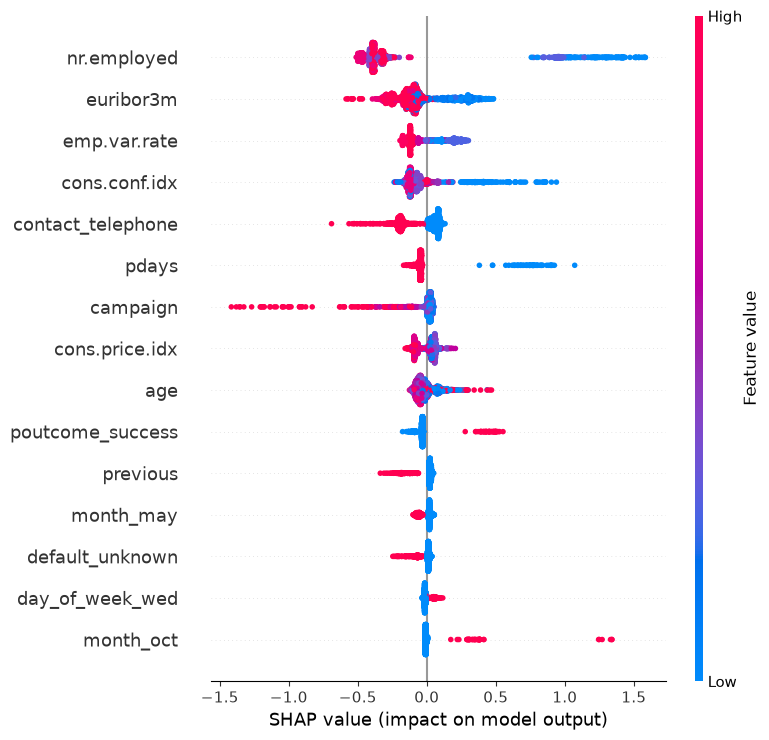


Sample customer (row index 40442)
Model score: 0.9703
Top 5 reasons pushing the subscription score UP:
  nr.employed                     value = 4991.600  |  SHAP = +1.516
  pdays                           value = 6.000  |  SHAP = +0.883
  poutcome_success                value = 1.000  |  SHAP = +0.496
  euribor3m                       value = 0.904  |  SHAP = +0.323
  age                             value = 65.000  |  SHAP = +0.145
Top 3 factors pulling the subscription score DOWN:
  day_of_week_wed                 value = 0.000  |  SHAP = -0.015
  poutcome_nonexistent            value = 0.000  |  SHAP = -0.023
  previous                        value = 3.000  |  SHAP = -0.139


In [14]:
import shap

rf_imp = pd.Series(rf_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
xgb_imp = pd.Series(xgb_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)

print("Top 15 features by Random Forest importance:")
for f, v in (rf_imp.head(15) * 100).items():
    print(f"  {f:30s}  {v:.2f}")

print("\nTop 15 features by XGBoost gain importance (% of total gain):")
for f, v in (xgb_imp.head(15) * 100).items():
    print(f"  {f:30s}  {v:.2f}")

rf_imp.head(15).sort_values().plot(kind='barh', title='Top 15 features (Random Forest)')
plt.show()

xgb_imp.head(15).sort_values().plot(kind='barh', title='Top 15 features (XGBoost gain)')
plt.show()

# SHAP on 2,000 test customers, using XGBoost
shap_sample = X_test.sample(2000, random_state=42)
shap_values = shap.TreeExplainer(xgb_model).shap_values(shap_sample)
shap.summary_plot(shap_values, shap_sample, max_display=15)

# Reasons for the highest-scored customer in the sample
i = xgb_model.predict_proba(shap_sample)[:, 1].argmax()
reasons = pd.Series(shap_values[i], index=shap_sample.columns).sort_values(ascending=False)
print(f"\nSample customer (row index {shap_sample.index[i]})")
print(f"Model score: {xgb_model.predict_proba(shap_sample)[i, 1]:.4f}")
print("Top 5 reasons pushing the subscription score UP:")
for f, v in reasons.head(5).items():
    print(f"  {f:30s}  value = {shap_sample.iloc[i][f]:.3f}  |  SHAP = {v:+.3f}")
print("Top 3 factors pulling the subscription score DOWN:")
for f, v in reasons.tail(3).items():
    print(f"  {f:30s}  value = {shap_sample.iloc[i][f]:.3f}  |  SHAP = {v:+.3f}")

**Findings**
- Random Forest top features: euribor3m 15.52%, nr.employed 12.77%, emp.var.rate 12.22%, cons.conf.idx 6.77% and age 6.17%. XGBoost gain: nr.employed 39.36%, cons.conf.idx 5.06%, emp.var.rate 4.45%, poutcome_success 3.26% and euribor3m 2.81%. Both lists highlight the economic-rate features and previous-campaign success.
- For the sample customer (row 40442), the model score is 0.9703. The main reasons pushing the score up are a lower nr.employed (4991.6, SHAP +1.516), pdays of 6 (+0.883), poutcome_success = 1 (+0.496), euribor3m 0.904 (+0.323) and age 65 (+0.145). previous (3, SHAP -0.139), poutcome_nonexistent and day_of_week_wed pulled the score down a little.
- **How to read this:** if both models highlight previous outcome and the economic-rate features, that story is robust. Month and macro rates may be specific to this 2008-2010 Portuguese campaign, so flag them as less portable than previous take-up or channel.

## Step 14: MLflow Tracking and Saving the Best Model
**What we do**
- Log all four models to MLflow, with their test ROC-AUC and PR-AUC, using a local SQLite file (`mlflow.db`) as the tracking store.
- Save the winning model, the feature list, the scaler, a flag for whether that model needs scaling, and the cut-off with `joblib`, so a later app can score a new campaign list the same way.

**Why it matters**
- MLflow keeps a record of every experiment, so the four models can be compared and the run can be reproduced.
- The saved file is exactly what a scoring job would load: the model alone is not enough, because a logistic winner would need the same scaler, and any cut-off policy must stay attached to the model.

**Domain link**
- A propensity model is re-scored every time a new campaign list is built, and re-trained as new outcomes arrive. Experiment tracking and a single model bundle make that handover repeatable.
- JD-based: "MLOps, model deployment and monitoring" and "MLflow". Deploying on AWS comes later.

**Interview line**
- "I logged all four models in MLflow and saved a joblib bundle with the winning model, the scaler, the feature list and the cut-off, which is what a campaign-scoring job would load." 

In [15]:
!pip install -q mlflow
import mlflow
import joblib
import os

mlflow.set_tracking_uri('sqlite:///mlflow.db')      # local database file
mlflow.set_experiment('bank-marketing-propensity')

sk_models = {
    'logistic_regression': (log_model, log_test_pred, 'sklearn'),
    'decision_tree': (tree_model, tree_test_pred, 'sklearn'),
    'random_forest': (rf_model, rf_test_pred, 'sklearn'),
    'xgboost': (xgb_model, xgb_test_pred, 'xgboost'),
}

for name, (model, t_pred, flavour) in sk_models.items():
    with mlflow.start_run(run_name=name):
        mlflow.log_params({'model': name})
        if name == 'xgboost':
            mlflow.log_params({
                'scale_pos_weight': float(pos_weight),
                'best_iteration': int(xgb_model.best_iteration),
            })
        mlflow.log_metric('roc_auc', roc_auc_score(y_test, t_pred))
        mlflow.log_metric('pr_auc', average_precision_score(y_test, t_pred))
        if flavour == 'xgboost':
            mlflow.xgboost.log_model(model, 'model')
        else:
            # cloudpickle avoids a newer MLflow skops check on tree models
            mlflow.sklearn.log_model(model, 'model', serialization_format='cloudpickle')
        print(f"MLflow run logged for {name}: {mlflow.active_run().info.run_id}")

# Map the winning display name to the object we will save
bundle_models = {
    'Logistic regression': (log_model, True),
    'Decision tree': (tree_model, False),
    'Random Forest': (rf_model, False),
    'XGBoost': (xgb_model, False),
}
best_model, needs_scaling = bundle_models[best_name]

bundle = {
    'model': best_model,
    'name': best_name,
    'features': list(X_train.columns),
    'scaler': scaler,
    'needs_scaling': needs_scaling,
    'threshold': threshold,
}
joblib.dump(bundle, 'bank_marketing_propensity.joblib')
print(f"\nBest model saved: {best_name}")
print(f"Model file: bank_marketing_propensity.joblib ({os.path.getsize('bank_marketing_propensity.joblib') / 1e6:.1f} MB)")

2026/11/15 17:41:50 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/15 17:41:50 INFO mlflow.store.db.utils: Updating database tables


2026/11/15 17:41:50 INFO mlflow.tracking.fluent: Experiment with name 'bank-marketing-propensity' does not exist. Creating a new experiment.


2026/11/15 17:41:51 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


2026/11/15 17:41:51 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/11/15 17:41:54 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


... (4 outputs left out)

MLflow run logged for decision_tree: 97b869411be04ceda5d04401d975c19e


2026/11/15 17:41:59 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


MLflow run logged for random_forest: 744e898979fb44b9819089097d984532


MLflow run logged for xgboost: 99a604bbeb83403dabf12dfd0b87994d

Best model saved: XGBoost
Model file: bank_marketing_propensity.joblib (0.3 MB)


**Findings**
- All four models were logged in MLflow: logistic regression fa6e367df29141cba3b9f113c7a62300, decision tree d06ddf60341a436db0596d8bb6e10a5d, Random Forest bf40ad6ce77d4419bac9b9536471f9cc, and XGBoost ff20a0732ab54678bed97be547f6e8c6.
- The winning model (XGBoost) was saved as bank_marketing_propensity.joblib (0.3 MB).
- **How to read this:** four logged runs plus one joblib bundle means the comparison is stored, and a later scoring job can reload the winner with the same features, scaler and cut-off.

## Summary for Interview
**Results**
- Data: 41,176 clients after dropping 12 duplicates; 4,639 subscribers, a subscription rate of 11.27%.
- Key EDA findings: previous success has a 65.1% subscription rate (vs 8.8% when there was no previous campaign); cellular 14.7% vs telephone 5.2%; age gap is significant but small (means 40.91 vs 39.91, Welch p = 1.843e-06). Duration is leakage (subscriber mean 553 seconds vs 221) and was dropped.
- Logistic regression baseline: ROC-AUC 0.7987, PR-AUC 0.4473.
- Decision tree (max_depth 4): ROC-AUC 0.7845, PR-AUC 0.4035.
- Random Forest: ROC-AUC 0.8125, PR-AUC 0.4695.
- XGBoost: ROC-AUC 0.8100, PR-AUC 0.4717, best trees 116. Winner by validation ROC-AUC (0.8147).
- Cut-off (validation-max F1): 0.71, test precision 48.29%, recall 54.85%, F1 51.36%.
- If we call the top 20%, we reach 66.3% of the subscribers (response rate 37.3%, lift 3.31).
- Top XGBoost features: nr.employed 39.36%, cons.conf.idx 5.06%, emp.var.rate 4.45%, poutcome_success 3.26% and euribor3m 2.81%.
- All four models are logged in MLflow (XGBoost run ff20a0732ab54678bed97be547f6e8c6). The winner was saved as bank_marketing_propensity.joblib (0.3 MB).

**Limitations**
- `duration` must stay out of the model. Including it would inflate the scores and make the model unusable for pre-call targeting.
- This file has no account balance, income or current product holdings, which a bank or an NBFC would usually have on an existing customer.
- `unknown` is a category, and `pdays = 999` is a sentinel value, not a real 999-day gap.
- Month and the macro features (`euribor3m`, `nr.employed`, `emp.var.rate`) reflect a Portuguese campaign from 2008 to 2010. They may not travel to another country, year or product, such as a Muthoot gold-loan or insurance offer.
- One-hot encoding was applied on the full file before the split, which is simple. In production the encoder should be fitted on the training set only.
- `class_weight` and `scale_pos_weight` inflate predicted probabilities. Scores rank well but need calibration before being used as actual probabilities.
- The cut-off was chosen by maximising F1 on the validation set, not from a real cost of a wasted call vs a missed subscriber. A later time period of campaigns would be a stronger check than a random test split.

**Next steps**
- Deployment: serve the saved joblib bundle through a FastAPI `/predict` endpoint or a batch job that scores a campaign list, containerised and hosted on AWS or Hugging Face Spaces.
- Monitoring: track the weekly call rate, the realised take-up of contacted customers, and drift in features such as job mix or previous-outcome mix; retrain when lift in the top 20% drops.
- Model: add balance, product-holding and recency features when they are available, fit the encoder on train only, calibrate probabilities, and set the call volume from real campaign capacity and offer value.

## Common Interview Questions
Short hints only. Answer in your own words using your numbers.

- **1. Why did you drop duration?**
  - Hint: it is the length of the call, only known after the call, which is after you already know yes or no. A model that uses it cannot decide who to call. This is leakage, and it is the first question most interviewers ask on this dataset.
- **2. Why both ROC-AUC and PR-AUC, and why not accuracy?**
  - Hint: about 11% subscribe, so a model that always says "no" is about 89% accurate and catches nobody. ROC-AUC is the ranking quality overall. PR-AUC focuses on the yes class and should be compared with the 11% random baseline.
- **3. Why show a shallow decision tree if Random Forest or XGBoost is stronger?**
  - Hint: a depth-4 tree with `plot_tree` is something a marketing or business head can follow. It is for the conversation and for the JD's "tree-based models". The stronger model is what I would actually use to rank the list.
- **4. How does this transfer to Muthoot (gold loans, deposits, insurance)?**
  - Hint: same problem shape - rank existing customers for a cross-sell or up-sell offer so a limited call or branch team reaches more takers. The labels and some features would change (product holdings, gold-loan value, recency). Month and Portuguese macro rates would not be copied across as-is.
- **5. Why a stratified 60/20/20 split, and why scale only for logistic regression?**
  - Hint: stratification keeps the subscription rate the same in each split. The scaler is fitted on train only, to avoid leakage. Logistic regression needs a common scale (`nr.employed` vs `euribor3m`). Tree splits do not.
- **6. What is lift, and what does "top 20% capture" mean?**
  - Hint: lift is how many times better a slice's yes-rate is than the overall rate. Capture is the share of all subscribers sitting in that slice. If we call the top 20% and reach well over 20% of the subscribers, the ranker is doing its job. A random 20% list would only reach about 20%.
- **7. When do you use a chi-square test vs a t-test?**
  - Hint: chi-square for a categorical vs the yes/no target (poutcome, job, contact). A t-test (or Welch) for a numeric vs the two classes (age here; this file has no balance). With 40,000 rows a tiny gap can have a small p-value, so I also report the size of the gap.
- **8. How do you explain a high score to a marketing head or a customer?**
  - Hint: SHAP gives the top reasons for that customer, in this file often previous outcome, a market rate, or channel. I would also keep a short reason-code list in production language ("previous take-up", "mobile contact", "retired").
- **9. How would you deploy and monitor this?**
  - Hint: log the four models in MLflow, save the winner with the scaler, feature list and cut-off in joblib, score a campaign list with a FastAPI endpoint or a batch job, and monitor take-up, lift in the top 20%, and feature drift as new campaign outcomes arrive.
- **10. What data issues should you flag on this dataset?**
  - Hint: duration leakage; `unknown` is a category, not a null; `pdays = 999` is a sentinel; there is no balance or product-holding data; month and macro features are from a 2008-2010 Portuguese campaign and may not travel; one-hot was done on the full file, which I would tighten to train-only in production.

## Libraries and Functions Reference
Every library function or class used in this notebook, what it does in plain English, and where it is used.

**pandas (pd)**
- `pd.read_csv(sep=';')`: loads the semicolon-separated campaign file; Step 1
- `DataFrame.shape`: number of rows and columns; Steps 1, 4 and 5
- `DataFrame.columns` / `list()`: column names; Steps 1, 4 and 5
- `DataFrame.dtypes`: type of each column; Step 1
- `DataFrame.head()`: first rows, to check the file loaded correctly; Step 1
- `DataFrame.isna().sum()`: counts Pandas missing values; Step 1
- `DataFrame.duplicated()`: marks exact duplicate rows; Step 1
- `DataFrame.drop_duplicates()`: removes those extra copies; Step 1
- `DataFrame.reset_index()`: renumbers rows after the drop; Step 1
- `DataFrame.select_dtypes()`: picks the string columns so we can count `unknown`; Step 1
- `Series.value_counts()`: counts yes vs no, or category volumes; Steps 1, 2 and 3
- `Series.mean()`: average, or the subscription rate on a 0/1 column; Steps 2, 3, 5 and 6
- `Series.median()`: middle value of age or duration; Steps 3 and 4
- `DataFrame.groupby()['y'].mean()`: subscription rate by category; Step 3
- `pd.crosstab()`: the count table used by the chi-square test; Step 3
- `DataFrame.drop(columns=)`: removes `duration` or the target column; Steps 4 and 6
- `pd.get_dummies()`: one-hot encodes the categorical columns; Step 5
- `DataFrame.copy()`: a separate copy so later edits do not hit a slice warning; Step 6
- `pd.Series()`: builds a labelled list of coefficients, importances or SHAP values; Steps 7 and 13
- `Series.abs()` / `Series.sort_values()`: rank coefficients or importances by size; Steps 7 and 13
- `Series.head()` / `Series.tail()`: first or last N items; Steps 5, 7 and 13
- `Series.plot()`: quick bar chart; Steps 2, 3 and 13
- `DataFrame.sample()`: random sample of rows for SHAP; Step 13
- `DataFrame.iloc[]`: picks a row by position in the SHAP sample; Step 13

**numpy (np)**
- `np.linspace()`: evenly spaced candidate cut-offs from 0.05 to 0.95; Step 11
- `np.argmax()`: position of the highest validation F1; Step 11
- `np.argsort()`: orders test scores from high to low for the decile table; Step 12
- `array.ravel()`: flattens the 2 x 2 confusion matrix into tn, fp, fn, tp; Step 11
- `array.argmax()`: position of the highest score in the SHAP sample; Step 13

**matplotlib.pyplot (plt)**
- `plt.hist()`: density histograms of age and of duration; Steps 3 and 4
- `plt.plot()` / `plt.axvline()` / `plt.axhline()`: ROC, PR and gains charts, plus reference lines; Steps 11 and 12
- `plt.bar()`: lift by decile; Step 12
- `plt.xlabel()` / `plt.ylabel()` / `plt.title()` / `plt.legend()`: chart labels; Steps 2, 3, 4, 8, 11, 12 and 13
- `plt.figure()`: starts a new chart so plots do not overlay; Steps 8, 11 and 12
- `plt.show()`: displays the chart; Steps 2, 3, 4, 8, 11, 12 and 13

**scipy.stats**
- `stats.chi2_contingency()`: chi-square test of association between a categorical feature and `y`; Step 3
- `stats.ttest_ind(equal_var=False)`: Welch t-test on age; Step 3

**scikit-learn**
- `train_test_split(stratify=)`: splits data and keeps the subscription rate the same; Step 6
- `StandardScaler`: puts features on mean 0 and standard deviation 1, fitted on train only, for logistic regression; Step 6
- `LogisticRegression(class_weight='balanced')`: the explainable baseline model; Step 7
- `DecisionTreeClassifier(max_depth=4)`: the shallow, readable tree; Step 8
- `plot_tree()`: draws that tree for a business audience; Step 8
- `RandomForestClassifier`: bagging tree model; Step 9
- `average_precision_score()`: PR-AUC; Steps 7, 8, 9, 10 and 11
- `roc_auc_score()`: ROC-AUC; Steps 7, 8, 9, 10 and 11
- `precision_recall_curve()` / `roc_curve()`: points for the PR and ROC plots; Step 11
- `confusion_matrix()`: counts of correct and wrong calls at the cut-off; Step 11
- `precision_score()` / `recall_score()` / `f1_score()`: metrics at the chosen cut-off; Step 11
- `.fit()` / `.predict_proba()`: trains a supervised model, then gives a subscription probability; Steps 7 to 13

**xgboost (xgb)**
- `xgb.XGBClassifier`: gradient-boosted trees (`scale_pos_weight` handles imbalance, `eval_metric='aucpr'` matches PR-AUC, `early_stopping_rounds=50` stops extra trees); Step 10
- `best_iteration`: the number of trees chosen by early stopping; Steps 10 and 14
- `feature_importances_`: gain importance of each feature, as a share of total gain; Step 13

**shap**
- `shap.TreeExplainer()`: builds a SHAP explainer for the XGBoost model; Step 13
- `explainer.shap_values()`: SHAP value for each feature on each sampled row; Step 13
- `shap.summary_plot()`: one chart of SHAP values for the sample; Step 13

**mlflow**
- `mlflow.set_tracking_uri()`: points logging at a local `mlflow.db` file; Step 14
- `mlflow.set_experiment()`: names the experiment; Step 14
- `mlflow.start_run()`: starts one logged run; Step 14
- `mlflow.log_params()` / `mlflow.log_metric()`: stores parameters and scores; Step 14
- `mlflow.sklearn.log_model()`: stores each scikit-learn model with its run; Step 14
- `mlflow.xgboost.log_model()`: stores the XGBoost model with its run; Step 14
- `mlflow.active_run().info.run_id`: the id printed so you can find the run later; Step 14

**joblib and os**
- `joblib.dump()`: saves the winning model, scaler, feature list, scaling flag and cut-off in one file; Step 14
- `os.walk()`: lists files under `/kaggle/input` so you can confirm the data path; first cell
- `os.path.getsize()`: file size of the saved joblib bundle; Step 14
- `os.path.join()`: builds each file path in the first-cell listing; first cell